## Part 1: TF-IDF by Hand

In [1]:
import re, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

print('spaCy', spacy.__version__)

spaCy 3.8.16


In [2]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()
X = vec.fit_transform(docs)
tbl = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                   index=['d1', 'd2', 'd3'])
print(tbl.round(3))

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000


In [3]:
# idf = ln((1 + N) / (1 + df)) + 1, N = 3 documents
idf = {'win':  np.log(4 / 2) + 1,
       'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1,
       'now':  np.log(4 / 4) + 1}
v = np.array(list(idf.values()))          # tf = 1 for each word in d1
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}


In [4]:
print('cosine(d2, d3) =', round(float(tbl.loc['d2'] @ tbl.loc['d3']), 3))

cosine(d2, d3) = 0.544


### Write it: Part 1

**IDF arithmetic** (smooth idf = ln((1 + N) / (1 + df)) + 1, with N = 3 documents)

- "free" appears in 2 of the 3 documents (d1 and d3), so df = 2:
  idf = ln((1 + 3) / (1 + 2)) + 1 = ln(4/3) + 1 = 0.288 + 1 = **1.288**
- "now" appears in all 3 documents, so df = 3:
  idf = ln((1 + 3) / (1 + 3)) + 1 = ln(1) + 1 = 0 + 1 = **1.000**

**Check for d1** (tf = 1 for each word, idf: win 1.693, free 1.288, cash 1.693, now 1.000):
the vector length is sqrt(1.693² + 1.288² + 1.693² + 1.000²) = sqrt(8.392) = 2.897, so
win = 1.693 / 2.897 = 0.584, free = 1.288 / 2.897 = 0.445, cash = 0.584, now = 1.000 / 2.897 = 0.345.
These match both of my printouts (sklearn and by hand).

**Why "now" gets the lowest weight:** it appears in every document, so it does not help to tell one document from another. The smooth IDF gives it the minimum possible value (1.000), while rarer words such as "win" and "cash" (each in only 1 document) get 1.693.

**Cosine similarity between d2 and d3** (rows are already length 1, so the cosine is the dot product).
The two documents share the words "call" and "now":
- call: 0.548 × 0.620 = 0.340
- now: 0.425 × 0.481 = 0.204

cosine(d2, d3) = 0.340 + 0.204 = **0.544**, which matches the 0.54 on slide 10 and my code output (0.544). The documents are fairly similar because they share two of their three words, but not identical, because "me" and "free" only appear in one of them.

## Part 2: Text Classification: Word vs Char N-grams

In [5]:
path = glob.glob('/kaggle/input/**/spam.csv', recursive=True)[0]
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



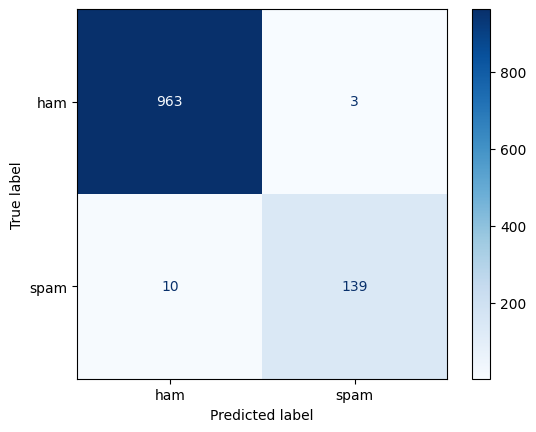

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42, stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

In [7]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


In [8]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    rep = classification_report(y_te, p, output_dict=True)['1']
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}  '
          f'spam P {rep["precision"]:.3f}  R {rep["recall"]:.3f}  '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')

word 1-2 grams  macro-F1 0.974  spam P 0.979  R 0.933  features 12,128
char 2-5 grams  macro-F1 0.982  spam P 0.986  R 0.953  features 36,449


In [9]:
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now',
          'kal milte hain, 5 baje',
          'bhai kal 5 baje milte hain, ghar se paisay le aana',
          'C@ll n0w & g3t FR33 rech@rge, r3ply W1N to 8080']
for name, clf in [('word', word_clf), ('char', char_clf)]:
    print(name, dict(zip(tricky, clf.predict_proba(tricky)[:, 1].round(2))))

word {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.99), 'kal milte hain, 5 baje': np.float64(0.19), 'bhai kal 5 baje milte hain, ghar se paisay le aana': np.float64(0.21), 'C@ll n0w & g3t FR33 rech@rge, r3ply W1N to 8080': np.float64(0.2)}
char {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12), 'bhai kal 5 baje milte hain, ghar se paisay le aana': np.float64(0.1), 'C@ll n0w & g3t FR33 rech@rge, r3ply W1N to 8080': np.float64(0.78)}


### Part 2

**Results**

| Model | macro-F1 | spam precision | spam recall | features |
|---|---|---|---|---|
| word 1-2 grams | 0.974 | 0.979 | 0.933 | 12,128 |
| char 2-5 grams | 0.982 | 0.986 | 0.953 | 36,449 |

The char model finished 0.008 ahead of the word model in macro-F1 (0.982 against 0.974) and also found more of the spam (recall 0.953 against 0.933). My explanation is that character n-grams work on small fragments of a word, so a disguised spelling still shares pieces with spam words the model has already seen, whereas a word model treats an unseen spelling as an unknown token. The char model also has about three times as many features (36,449 against 12,128).

Only 13.4% of the test messages are spam (149 of 1,115). A model that said "ham" every time would still score 966/1115 = 0.866 accuracy without catching a single spam message, so accuracy is a poor measure here. Macro-F1 gives both classes equal weight, which is why I report it.
**Top features (word model)**

Most spam-like: call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your
Most ham-like: my, me, ok, that, it, but, ll, gt, lt, can, what, da

- Sensible features: call, txt, free, claim, reply, stop and mobile are words that ask the reader to act or promise a reward. On the ham side, my, me, ok and can are ordinary conversation words.
- Features that look like shortcuts: "uk" probably reflects where the dataset was collected (many UK promotional messages), not a general property of spam. "gt" and "lt" are leftovers of HTML encoding (&gt; and &lt;) that appear in a group of ham messages, so they describe the file, not the meaning. "www" is partly sensible (spam often has links) but a spammer can avoid it, and generic words like "to" and "your" are weak evidence on their own.

**Tricky messages**

| Message | word | char |
|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now | 0.99 | 0.85 |
| kal milte hain, 5 baje | 0.19 | 0.12 |
| bhai kal 5 baje milte hain, ghar se paisay le aana | 0.21 | 0.10 |
| C@ll n0w & g3t FR33 rech@rge, r3ply W1N to 8080 | 0.20 | 0.78 |

Both models rated my Roman Urdu message as ham, which is correct. On my disguised spam message the word model missed it (0.20) and the char model caught it (0.78). A likely reason is that tokens like "FR33", "r3ply" and "rech@rge" never appeared in training, so the word model ignores them, while the char model still sees fragments such as "ply", "rech" and "arge". This is only one message per case, so I can only conclude that char n-grams were more robust on this example, not that they are always better.

**Misclassified messages (word model, 13 errors: 10 missed spam, 3 false alarms)**

1. "Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?" (spam, p=0.09): ambiguous, it reads like a joke and probably comes from a joke subscription service, so the label depends on context.
2. "Hi ya babe x u 4goten bout me?' scammers getting smart.. Beware!" (spam, p=0.14): ambiguous, the text warns about a scam, though it is a copy of a scam message.
3. "ringtoneking 84484" (spam, p=0.19): model error, it is real spam but only two tokens, so there is little context.
4. "For sale - arsenal dartboard..." (spam, p=0.21): ambiguous, it looks like a normal advert and probably comes from a joke/ad subscription.
5. "ROMCAPspam Everyone around should be responding well to your presence..." (spam, p=0.25): model error, a horoscope-subscription message with an unusual token.
6. "Sorry I missed your call... I'm on 07090201529" (spam, p=0.28): ambiguous, it reads like a normal message but the callback number is the trap.
7. "Latest News! Police station toilet stolen..." (spam, p=0.31): ambiguous, a joke message like #1.
8. "FreeMsg Hey there darling... std chgs to send" (spam, p=0.41): model error, clear spam just under the 0.5 threshold.
9. "Download as many ringtones as u like... Txt Sir to 80082" (spam, p=0.42): model error, clear spam just under the threshold.
10. "Can U get 2 phone NOW?... Call me NOW on 09096102316" (spam, p=0.46): model error, clear spam just under the threshold.
11. "We have sent JD for Customer Service cum Accounts Executive to ur mail id..." (ham, p=0.62): ambiguous, it is a commercial-sounding job message.
12. "Ok... Ur typical reply..." (ham, p=0.64): model error, an ordinary reply pushed up by words like "reply".
13. "Waiting for your call." (ham, p=0.85): model error, ordinary words such as "call" and "your" are strong spam features.

## Part 3: Named Entity Recognition, Measured

In [10]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

In [11]:
nlp_base = spacy.load('en_core_web_sm')

sentences = [
    'Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    print([(e.text, e.label_) for e in nlp_base(s).ents])

gold = [
    {('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'), ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'), ('30/09/2026', 'DATE')},
    {('Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'), ('Bilal Ahmed', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def ner_scores(model, sents, gold_sets):
    tp = fp = fn = 0
    for s, g in zip(sents, gold_sets):
        pred = {(e.text, e.label_) for e in model(s).ents}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f, 3)}

print('Provided set, spaCy out of the box:', ner_scores(nlp_base, sentences, gold))

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]
Provided set, spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


In [12]:
def make_nlp_with_rules(patterns):
    n = spacy.load('en_core_web_sm')
    n.add_pipe('entity_ruler', before='ner').add_patterns(patterns)
    return n

provided_patterns = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'}, {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE', 'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
]
nlp_prov = make_nlp_with_rules(provided_patterns)

for s in sentences:
    print([(e.text, e.label_) for e in nlp_prov(s).ents])

print('Provided set, with entity ruler:', ner_scores(nlp_prov, sentences, gold))

[('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'), ('30/09/2026', 'DATE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('Jazz', 'ORG'), ('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]
Provided set, with entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


In [13]:
dom_sents = [
    # dev set: rules sirf in 5 se likhne hain
    'Farmer Muhammad Aslam from Multan reported late blight on his tomato crop on 14 October 2026.',
    'Engro Fertilizers sold 50 kg of urea to Rashid Mehmood in Faisalabad for Rs. 4,500.',
    'Dr. Sana Iqbal of the University of Agriculture Faisalabad inspected the potato fields on 3 November 2026.',
    'The Punjab Agriculture Department advised spraying Mancozeb in Sahiwal on Friday.',
    'Ali Traders in Okara bought pesticide worth PKR 12,000 on 05/10/2026.',
    # held-out test: rules likhte waqt inhein mat dekhna
    'Bilal Hussain from Bahawalpur reported yellow leaf curl on tomato plants on 20 October 2026.',
    'Fauji Fertilizer delivered 100 kg of DAP to Kasur for Rs. 18,500.',
    'Dr. Nadia Rauf of PARC Islamabad confirmed bacterial spot in pepper fields on Tuesday.',
    'Call Zarai Taraqiati Bank about a loan of Rs. 300,000 for Imran Shah.',
    'The potato harvest in Sialkot ended on 28/11/2026 with 40 tonnes sold to Lahore.']

for i, s in enumerate(dom_sents, 1):
    print(i, [(e.text, e.label_) for e in nlp_base(s).ents])

1 [('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE'), ('14 October 2026', 'DATE')]
2 [('Engro Fertilizers', 'PERSON'), ('50 kg', 'QUANTITY'), ('Rashid Mehmood', 'PERSON'), ('Faisalabad', 'GPE'), ('4,500', 'CARDINAL')]
3 [('Sana Iqbal', 'PERSON'), ('the University of Agriculture Faisalabad', 'ORG'), ('3 November 2026', 'DATE')]
4 [('The Punjab Agriculture Department', 'ORG'), ('Mancozeb', 'PERSON'), ('Sahiwal', 'GPE'), ('Friday', 'DATE')]
5 [('Ali Traders', 'PERSON'), ('Okara', 'ORG'), ('PKR', 'ORG')]
6 [('Bilal Hussain', 'PERSON'), ('Bahawalpur', 'GPE'), ('20 October 2026', 'DATE')]
7 [('Fauji Fertilizer', 'PERSON'), ('100 kg', 'QUANTITY'), ('DAP', 'ORG'), ('Kasur for Rs', 'ORG'), ('18,500', 'CARDINAL')]
8 [('Nadia Rauf', 'PERSON'), ('PARC Islamabad', 'ORG'), ('Tuesday', 'DATE')]
9 [('Call Zarai Taraqiati Bank', 'ORG'), ('300,000', 'CARDINAL'), ('Imran Shah', 'PERSON')]
10 [('Sialkot', 'PERSON'), ('28/11/2026', 'DATE'), ('40 tonnes', 'QUANTITY'), ('Lahore', 'GPE')]


In [14]:
dom_gold = [
    {('Muhammad Aslam', 'PERSON'), ('Multan', 'GPE'), ('14 October 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('50 kg', 'QUANTITY'), ('Rashid Mehmood', 'PERSON'),
     ('Faisalabad', 'GPE'), ('Rs. 4,500', 'MONEY')},
    {('Sana Iqbal', 'PERSON'), ('University of Agriculture Faisalabad', 'ORG'), ('3 November 2026', 'DATE')},
    {('Punjab Agriculture Department', 'ORG'), ('Sahiwal', 'GPE'), ('Friday', 'DATE')},
    {('Ali Traders', 'ORG'), ('Okara', 'GPE'), ('PKR 12,000', 'MONEY'), ('05/10/2026', 'DATE')},
    {('Bilal Hussain', 'PERSON'), ('Bahawalpur', 'GPE'), ('20 October 2026', 'DATE')},
    {('Fauji Fertilizer', 'ORG'), ('100 kg', 'QUANTITY'), ('Kasur', 'GPE'), ('Rs. 18,500', 'MONEY')},
    {('Nadia Rauf', 'PERSON'), ('PARC', 'ORG'), ('Islamabad', 'GPE'), ('Tuesday', 'DATE')},
    {('Zarai Taraqiati Bank', 'ORG'), ('Rs. 300,000', 'MONEY'), ('Imran Shah', 'PERSON')},
    {('Sialkot', 'GPE'), ('28/11/2026', 'DATE'), ('40 tonnes', 'QUANTITY'), ('Lahore', 'GPE')}]

print(len(dom_gold), 'sentences,', sum(len(g) for g in dom_gold), 'gold entities')

10 sentences, 36 gold entities


In [15]:
domain_patterns = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'}, {'LIKE_NUM': True}]},
    {'label': 'DATE', 'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Ali Traders'},
    {'label': 'ORG', 'pattern': 'Punjab Agriculture Department'},
    {'label': 'ORG', 'pattern': 'University of Agriculture Faisalabad'},
    {'label': 'GPE', 'pattern': 'Okara'},
    # yahan aur rules jodo, lekin sirf sentences 1 se 5 dekh kar
]
nlp_dom = make_nlp_with_rules(domain_patterns)

dev, held = slice(0, 5), slice(5, 10)
for name, m in [('spaCy alone', nlp_base), ('spaCy + my rules', nlp_dom)]:
    print(f'{name:18s} dev  :', ner_scores(m, dom_sents[dev], dom_gold[dev]))
    print(f'{name:18s} held :', ner_scores(m, dom_sents[held], dom_gold[held]))

print('\nHeld-out mein ab bhi kya galat hai:')
for s, g in zip(dom_sents[held], dom_gold[held]):
    pr = {(e.text, e.label_) for e in nlp_dom(s).ents}
    print('\n', s, '\n   missed:', g - pr, '\n   wrong :', pr - g)

spaCy alone        dev  : {'precision': 0.5, 'recall': 0.5, 'f1': 0.5}
spaCy alone        held : {'precision': 0.556, 'recall': 0.556, 'f1': 0.556}
spaCy + my rules   dev  : {'precision': 0.895, 'recall': 0.944, 'f1': 0.919}
spaCy + my rules   held : {'precision': 0.667, 'recall': 0.667, 'f1': 0.667}

Held-out mein ab bhi kya galat hai:

 Bilal Hussain from Bahawalpur reported yellow leaf curl on tomato plants on 20 October 2026. 
   missed: set() 
   wrong : set()

 Fauji Fertilizer delivered 100 kg of DAP to Kasur for Rs. 18,500. 
   missed: {('Kasur', 'GPE'), ('Fauji Fertilizer', 'ORG')} 
   wrong : {('Kasur for', 'ORG'), ('Fauji Fertilizer', 'PERSON'), ('DAP', 'ORG')}

 Dr. Nadia Rauf of PARC Islamabad confirmed bacterial spot in pepper fields on Tuesday. 
   missed: {('PARC', 'ORG'), ('Islamabad', 'GPE')} 
   wrong : {('PARC Islamabad', 'ORG')}

 Call Zarai Taraqiati Bank about a loan of Rs. 300,000 for Imran Shah. 
   missed: {('Zarai Taraqiati Bank', 'ORG')} 
   wrong : {('Call 

### Write it: Part 3

| Set | spaCy alone | spaCy + rules |
|---|---|---|
| Provided sentences (6 sentences, 16 gold entities) | 0.533 | 0.875 |
| My dev set (sentences 1-5, 18 gold entities) | 0.500 | 0.919 |
| My held-out set (sentences 6-10, 18 gold entities) | 0.556 | 0.667 |

On my dev sentences the rules lifted F1 from 0.500 to 0.919, but on the held-out sentences the lift was much smaller (0.556 to 0.667). The reason is that I wrote the rules while looking at the dev sentences, so they fit those exact names and formats. The held-out figure is the honest one: the general rules for money and dd/mm/yyyy dates carried over, while the rules for specific names did not, because the held-out sentences contain companies and places that I had never listed.

**Remaining errors after the rules (held-out set, 6 missed and 6 wrong)**

- "Fauji Fertilizer" labelled PERSON and "Sialkot" labelled PERSON: these are new names. More rules would only fix names I have already seen, so I would train or fine-tune a model on annotated agriculture text, which can learn that a name followed by "Fertilizer" or a place after "in" is not a person.
- "Kasur for" and "Call Zarai Taraqiati Bank" (boundary errors): the span is too long. I would fix these with rule patterns or a small post-processing step that strips leading verbs like "Call" and trailing words like "for".
- "PARC Islamabad" as one ORG instead of "PARC" (ORG) and "Islamabad" (GPE): this partly depends on my annotation choice. A rule for "PARC" would fix it on this sentence but would not generalise.
- "DAP" labelled ORG: it is a fertilizer name. A short list of crop-input names (DAP, urea, Mancozeb) as rules would fix this, because that list is small and stable.

My conclusion: rules are good for fixed formats and small closed lists (money, dates, input names), but open-ended names of people, companies and places need a model trained on domain data.

## Part 4: Regex Fields with Negative Tests

In [16]:
PATTERNS = {
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
    # mere agriculture patterns
    'dose':    r'\b\d+(?:\.\d+)?\s?(?:ml|g|kg|l)\s?/\s?(?:l|acre|ha)\b',
    'area':    r'\b\d+(?:\.\d+)?\s?(?:acres?|hectares?|ha|kanals?|marlas?)\b',
    'leaf_id': r'\bLeaf\s?\d{1,3}\b',
}

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', True),
    ('Total Rs. 12,500.50 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@engro.com.pk', True),
    ('Order 12345678901234 shipped', False),             # CNIC nahi hona chahiye
    ('Room 0300 on floor 3', False),                     # mobile nahi hona chahiye
    # mere domain ke positive tests
    ('Spray Mancozeb at 2.5 ml/L on 12 acres', True),
    ('Photo of GHLB Leaf 23 taken on 05/10/2026', True),
    # mere domain ke negative tests
    ('Applied 25 kg of urea yesterday', False),          # per-unit nahi, dose nahi
    ('He said 12 hats and Leaf 12345 were lost', False), # "ha" lafz ke andar, aur 5-digit leaf id
]
for text, expect in tests:
    print(f'{str(expect):5s} {extract_fields(text)}  <- {text}')

True  {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']}  <- CNIC 35202-1234567-1, mobile +92 300 1234567
True  {'amount': ['12,500.50'], 'date': ['05/10/2026']}  <- Total Rs. 12,500.50 paid on 05/10/2026
True  {'email': ['info@engro.com.pk'], 'invoice': ['4417']}  <- Invoice No. 4417 from info@engro.com.pk
False {}  <- Order 12345678901234 shipped
False {}  <- Room 0300 on floor 3
True  {'dose': ['2.5 ml/L'], 'area': ['12 acres']}  <- Spray Mancozeb at 2.5 ml/L on 12 acres
True  {'date': ['05/10/2026'], 'leaf_id': ['Leaf 23']}  <- Photo of GHLB Leaf 23 taken on 05/10/2026
False {}  <- Applied 25 kg of urea yesterday
False {}  <- He said 12 hats and Leaf 12345 were lost


In [17]:
loose = {
    'mobile (loose)': r'0?3\d{2}[- ]?\d{7}',     # \b nahi, +92 nahi, 0 optional
    'area (loose)':   r'\d+\s?(?:ha)',            # \b nahi
    'leaf_id (loose)': r'Leaf\s?\d+',             # digits ki limit nahi
    'dose (loose)':   r'\d+\s?(?:ml|g|kg|l)\s?/?\s?(?:l|acre|ha)?',  # "/" aur unit optional
}
neg_tests = ['Order 12345678901234 shipped',
             'He said 12 hats and Leaf 12345 were lost',
             'Applied 25 kg of urea yesterday',
             'Ref 9903001234567 closed']
for name, pat in loose.items():
    print(name)
    for t in neg_tests:
        print('   ', re.findall(pat, t, flags=re.IGNORECASE), '<-', t)

mobile (loose)
    ['3456789012'] <- Order 12345678901234 shipped
    [] <- He said 12 hats and Leaf 12345 were lost
    [] <- Applied 25 kg of urea yesterday
    ['03001234567'] <- Ref 9903001234567 closed
area (loose)
    [] <- Order 12345678901234 shipped
    ['12 ha'] <- He said 12 hats and Leaf 12345 were lost
    [] <- Applied 25 kg of urea yesterday
    [] <- Ref 9903001234567 closed
leaf_id (loose)
    [] <- Order 12345678901234 shipped
    ['Leaf 12345'] <- He said 12 hats and Leaf 12345 were lost
    [] <- Applied 25 kg of urea yesterday
    [] <- Ref 9903001234567 closed
dose (loose)
    [] <- Order 12345678901234 shipped
    [] <- He said 12 hats and Leaf 12345 were lost
    ['25 kg '] <- Applied 25 kg of urea yesterday
    [] <- Ref 9903001234567 closed


### Write it: Part 4

**My domain patterns**

| Field | Pattern | Example it should match |
|---|---|---|
| dose | `\b\d+(?:\.\d+)?\s?(?:ml\|g\|kg\|l)\s?/\s?(?:l\|acre\|ha)\b` | 2.5 ml/L |
| area | `\b\d+(?:\.\d+)?\s?(?:acres?\|hectares?\|ha\|kanals?\|marlas?)\b` | 12 acres |
| leaf_id | `\bLeaf\s?\d{1,3}\b` | Leaf 23 |

I also kept the lab patterns for cnic, mobile, amount, date, email and invoice.

**Test results**

| Test text | Expected | Result |
|---|---|---|
| CNIC 35202-1234567-1, mobile +92 300 1234567 | match | cnic, mobile found |
| Total Rs. 12,500.50 paid on 05/10/2026 | match | amount, date found |
| Invoice No. 4417 from info@engro.com.pk | match | email, invoice found |
| Spray Mancozeb at 2.5 ml/L on 12 acres | match | dose 2.5 ml/L, area 12 acres found |
| Photo of GHLB Leaf 23 taken on 05/10/2026 | match | leaf_id Leaf 23, date found |
| Order 12345678901234 shipped | no match | {} |
| Room 0300 on floor 3 | no match | {} |
| Applied 25 kg of urea yesterday | no match | {} |
| He said 12 hats and Leaf 12345 were lost | no match | {} |

All 5 positive tests matched and all 4 negative tests returned nothing (2 negative tests are from the lab and 2 are my own: the urea quantity and the "12 hats / Leaf 12345" sentence).

**A pattern that matched too much, and the fix**

My first (loose) version of the `mobile` pattern was `0?3\d{2}[- ]?\d{7}`. It found "3456789012" inside "Order 12345678901234" and "03001234567" inside "Ref 9903001234567", which are not phone numbers. The loose pattern had no word boundary, so it could start in the middle of a longer number. I fixed it by anchoring the start with `\b0` (or `\+92`) and the end with `\b`, and by fixing the digit counts (`3\d{2}` then exactly `\d{7}`). The final pattern also ignored "Room 0300 on floor 3" because it needs the full 3 + 2 digits + 7 digits shape.

The same idea fixed my other patterns:
- `area`: loose `\d+\s?(?:ha)` matched "12 ha" inside "12 hats". Adding `\b` at the end stops the match inside a word.
- `leaf_id`: loose `Leaf\s?\d+` accepted "Leaf 12345". Limiting the number to `\d{1,3}` with `\b` rejects it.
- `dose`: loose version made the "/" and the second unit optional, so "25 kg" of urea looked like a dose. Making "/" and the per-unit (L, acre, ha) compulsory means only real dose rates match.

Lesson: a pattern is only as good as its negative tests, because a loose pattern passes every positive test.

## Part 5: Character Error Rate and OCR Repair

In [18]:
def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} CER {cer(ref, fixed):.3f}')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


In [19]:
import os, matplotlib
from PIL import Image, ImageDraw, ImageFont
import easyocr, torch

# DejaVuSans font matplotlib ke saath aata hai
font_path = os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf')
print('font:', font_path, '| exists:', os.path.exists(font_path))
font = ImageFont.truetype(font_path, 30)

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417 Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567', 'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
norm = lambda s: ' '.join(s.split())
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print(raw)
print(f'CER raw {cer(truth, raw):.3f}   after fixes {cer(truth, clean):.3f}')

font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf | exists: True
Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000


### Write it: Part 5

**Hand-made OCR errors (context rules)**

| Reference | OCR output | CER before | CER after fix_ocr |
|---|---|---|---|
| Invoice No. 4417 | Invoice N0. 4417 | 0.062 | 0.000 |
| Total: PKR 12,500 | Total: PKR 12,5O0 | 0.059 | 0.000 |
| Due 30/09/2026 | Due 3O/09/2O26 | 0.143 | 0.000 |

The rules work because they only change a letter into a digit when it sits inside or next to digits (for example, "O" between digits becomes "0", and "N0." becomes "No."). Each fixed pair needed 1 to 2 character edits, so CER dropped from between 0.059 and 0.143 to exactly 0.

**EasyOCR on the synthetic invoice**

OCR output: `Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000`

CER raw = 0.000, CER after fixes = 0.000.

The raw CER was already zero, so there was nothing for the repair rules to correct. It is also a useful check that `fix_ocr` did not damage correct text (CER stayed 0.000).

**Why this image is easier than a real phone photo**

This invoice is rendered by the computer: black text on a pure white background, a clean sans-serif font at a large size, straight lines, no noise, and no compression. A real phone photo of a receipt or pesticide bag has uneven lighting and shadows, blur, perspective and tilt, creased or curved paper, small or faded print, and JPEG compression. Characters such as 0/O, 1/l/I and 5/S are exactly the ones that get confused when the image is poor, which is the situation the repair rules were designed for.

**What I expect on my own documents**

On real scans I expect the raw CER to be above zero, roughly 2 to 5 percent on clear scans and noticeably higher on phone photos taken in poor light. This is only my estimate and I would confirm it by measuring CER on at least five real documents with hand-typed reference text. The correction rules should help with numbers such as dates, amounts and invoice numbers, but they cannot repair wrong letters inside ordinary words.

## Part 6: Image + Text Case Record, with Privacy

In [20]:
def mask_pii(text):
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


In [21]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms

W6_PATH = glob.glob('/kaggle/input/**/week6_model.pt', recursive=True)[0]
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('Loaded', W6_PATH, '| classes:', classes, '| backbone:', ckpt['backbone'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf_img = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf_img(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

# Mere domain ke warning words (word-start match, taake 'rot' 'rotation' par na chale)
URGENT = ['spreading', 'blight', 'wilting', 'yellow', 'rot', 'mites', 'curl', 'dying', 'lesion']

def text_evidence(note):
    doc = nlp_dom(note)
    low = note.lower()
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if re.search(r'\b' + k, low)]}

Loaded /kaggle/input/datasets/amanriaz749/week6model/week6_model.pt | classes: ['diseased', 'healthy'] | backbone: resnet18


In [22]:
def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)                      # extraction se PEHLE masking
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified agronomist decides.'}

# PlantVillage se example images (folder ke naam apne dataset ke mutabiq)
root = glob.glob('/kaggle/input/**/PlantVillage', recursive=True)[0]
def first_image(folder_part):
    d = [x for x in sorted(glob.glob(root + '/*')) if folder_part.lower() in x.lower()][0]
    return sorted(glob.glob(d + '/*'))[0]

DISEASED_IMG = first_image('Tomato_Late_blight')
HEALTHY_IMG  = first_image('Tomato_healthy')
print(DISEASED_IMG)
print(HEALTHY_IMG)
POSITIVE = 'diseased'

note = ('Farmer Imran Shah from Multan reports brown patches spreading on tomato leaves after rain. '
        'Field visited on 12/10/2026, 4 acres affected. Mobile 0300-1234567, CNIC 35202-1234567-1.')
rec = case_record(DISEASED_IMG, note, positive=POSITIVE)
out = json.dumps(rec, indent=2, ensure_ascii=False)
print(out)

# Leak check: yeh teeno JSON mein nahi hone chahiyen
for secret in ['0300-1234567', '1234567', '35202']:
    print(f'leak check {secret!r}:', 'LEAK!' if secret in out else 'ok')

/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato_Late_blight/0003faa8-4b27-4c65-bf42-6d9e352ca1a5___RS_Late.B 4946.JPG
/kaggle/input/datasets/emmarex/plantdisease/PlantVillage/Tomato_healthy/000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG
{
  "image": "0003faa8-4b27-4c65-bf42-6d9e352ca1a5___RS_Late.B 4946.JPG",
  "image_probabilities": {
    "diseased": 1.0,
    "healthy": 0.0
  },
  "note_masked": "Farmer Imran Shah from Multan reports brown patches spreading on tomato leaves after rain. Field visited on 12/10/2026, 4 acres affected. Mobile [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [
      [
        "Farmer Imran Shah",
        "PERSON"
      ],
      [
        "Multan",
        "GPE"
      ],
      [
        "12/10/2026",
        "DATE"
      ],
      [
        "4 acres",
        "QUANTITY"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "

In [23]:
note2 = 'Farmer reports yellowing and wilting spreading across the field, 2 acres affected.'
rec2 = case_record(HEALTHY_IMG, note2, positive=POSITIVE)
print(json.dumps(rec2, indent=2, ensure_ascii=False))

{
  "image": "000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG",
  "image_probabilities": {
    "diseased": 0.0,
    "healthy": 1.0
  },
  "note_masked": "Farmer reports yellowing and wilting spreading across the field, 2 acres affected.",
  "text_evidence": {
    "entities": [
      [
        "2 acres",
        "QUANTITY"
      ]
    ],
    "fields": {
      "area": [
        "2 acres"
      ]
    },
    "urgent_terms": [
      "spreading",
      "wilting",
      "yellow"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "note mentions: spreading, wilting, yellow"
  ],
  "disclaimer": "Decision support only; a qualified agronomist decides."
}


### Write it: Part 6

**My JSON record** (diseased tomato late-blight image + field note)

```json
{
  "image": "0003faa8-4b27-4c65-bf42-6d9e352ca1a5___RS_Late.B 4946.JPG",
  "image_probabilities": {"diseased": 1.0, "healthy": 0.0},
  "note_masked": "Farmer Imran Shah from Multan reports brown patches spreading on tomato leaves after rain. Field visited on 12/10/2026, 4 acres affected. Mobile [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [["Farmer Imran Shah", "PERSON"], ["Multan", "GPE"], ["12/10/2026", "DATE"],
                 ["4 acres", "QUANTITY"], ["CNIC", "ORG"], ["CNIC", "ORG"]],
    "fields": {"date": ["12/10/2026"], "area": ["4 acres"]},
    "urgent_terms": ["spreading"]
  },
  "decision": "REFER",
  "reasons": ["image model: P(diseased) = 1.00", "note mentions: spreading"],
  "disclaimer": "Decision support only; a qualified agronomist decides."
}
```

**Privacy check:** I searched the JSON for "0300-1234567", "1234567" and "35202". None appear, because `mask_pii` runs before entity and field extraction.

**Do the reasons make sense?** Yes. The image model gives P(diseased) = 1.00 on a late-blight leaf, and the note independently mentions "spreading", which is a warning word from my domain list. Two separate sources agree, so REFER is well supported.

**A wrong entity:** spaCy labelled "CNIC" as an ORG (twice). This comes from the word "CNIC" and the placeholder "[CNIC]" in the masked note, not from a real organisation. The person span "Farmer Imran Shah" also swallowed the title "Farmer". I consider both harmless in this record, because the placeholder holds no personal data and the decision uses only the image probability and the urgent terms, never the entity list. They would become a problem if a later step counted ORG entities or used the person span as a lookup key. To prepare for that I would drop placeholder tokens from the entity list and strip titles before such a step.

**Image and note disagree:** I paired a healthy tomato leaf (P(healthy) = 1.00) with the note "yellowing and wilting spreading across the field, 2 acres affected". The system returned REFER with the reason "note mentions: spreading, wilting, yellow" and no image reason. This is the safe direction (a missed disease costs more than a false alarm), but the record does not say that the two sources disagree. Two possible explanations are that the photo shows one healthy leaf while the problem is elsewhere in the field, or that the image model is overconfident on a type of problem it did not learn (its confidence is exactly 1.00, and my Week 6 test AUC was also 1.000, which I treated as a warning sign). My system should add an explicit "conflict" flag and send such cases to a human agronomist with both pieces of evidence, instead of letting either source overrule the other silently.

## Check Your Understanding

**1. A word appears in 9 of 1,000 documents. Compute its smooth IDF.**

idf = ln((1 + N) / (1 + df)) + 1, with N = 1000 and df = 9

idf = ln(1001 / 10) + 1 = ln(100.1) + 1 = 4.606 + 1 = **5.606**

A word this rare gets a high weight (compare "now" in Part 1, which appears in every document and got the minimum idf of 1).

**2. Why can lowercasing hurt a spam classifier?**

Spam often uses ALL CAPS words such as FREE, WIN, URGENT or CLAIM to attract attention. Lowercasing turns "FREE" into "free", which also appears in normal messages, so the capitalisation signal is lost and the two uses are mixed together. Also, the shouting style itself (many capitalised words) is a feature that disappears. (scikit-learn's TfidfVectorizer lowercases by default, so in my experiment this signal was already removed unless I set lowercase=False.)

**3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right.**

- precision = correct / predicted = 6 / 8 = **0.75**
- recall = correct / gold = 6 / 10 = **0.60**
- F1 = 2PR / (P + R) = 2 × 0.75 × 0.60 / (0.75 + 0.60) = 0.90 / 1.35 = **0.667**

**4. Reference "PKR 4,500" (9 characters), OCR output "PKR 4,5OO".**

Comparing character by character, the two zeros in "500" were read as the letter O, so there are 2 substitutions, 0 deletions and 0 insertions. The edit distance is 2.

CER = 2 / 9 = **0.222**

**5. Image model says 0.30, text model says 0.80, w = 0.5. Fused probability?**

fused = w × p_image + (1 − w) × p_text = 0.5 × 0.30 + 0.5 × 0.80 = 0.15 + 0.40 = **0.55**

With a threshold of 0.5 this would be flagged as positive, even though the image model alone (0.30) would not.

**6. Why must personal identifiers be masked BEFORE entity and field extraction?**

Masking only the displayed note is not enough, because the extraction functions would still read the original text and put the identifiers into their own output (the entities list and the fields dictionary), which are also logged and shared. In my own case record, the phone number 0300-1234567 would have appeared inside text_evidence if extraction ran first. Masking first means that every later step, including NER and regex, only ever sees "[PHONE]" and "[CNIC]". It also avoids model mistakes on raw identifiers: in Part 3, spaCy labelled the phone number "0300-1234567" as a DATE. I checked this in my JSON by searching for "0300-1234567", "1234567" and "35202", and none appeared.